In [1]:
import pandas as pd
import yfinance as yf
import matplotlib.pylab as plt


# Joint Probability

Joint Probability - probability of 2 events happen toogether

Independent Event
P(A and B) = P(A) x P(B)

Not independent
P(A and B) = P(A) x P(B|A)

In [2]:
sp500 = yf.download("^GSPC", period="10y")[["Close"]]
sp500.columns = ["SP500"]
sp500_returns = sp500["SP500"].pct_change(fill_method=None)

usdx = yf.download("DX-Y.NYB", period="10y")[["Close"]]
usdx.columns = ["USDX"]
usdx_returns = usdx["USDX"].pct_change(fill_method=None)

df = pd.concat([sp500_returns, usdx_returns], axis=1)
df.columns = ["SP500", "USDX"]
df = df.dropna()

CRASH_METRIC = -0.03
RISE_METRIC = 0.01


P_A = len(df[df["SP500"] < CRASH_METRIC]) / len(df)
P_B = len(df[df["USDX"] > RISE_METRIC]) / len(df)

P_AB = len(df[(df["SP500"] < CRASH_METRIC) & (df["USDX"] > RISE_METRIC)]) / len(df)

print(f"P(SP500 Crash) : {P_A*100:.2f} %")
print(f"P(USDX Rises)  : {P_B*100:.2f} %")
print(f"P(Both Happen) : {P_AB*100:.2f} %")


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

P(SP500 Crash) : 1.31 %
P(USDX Rises)  : 1.12 %
P(Both Happen) : 0.16 %


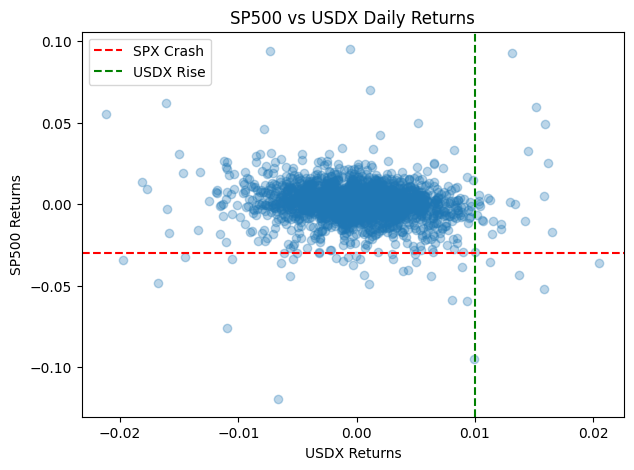

In [11]:
plt.figure(figsize=(7,5))
plt.scatter(df["USDX"], df["SP500"], alpha=0.3)
plt.axhline(y=CRASH_METRIC, color="red", linestyle="--", label = "SPX Crash")
plt.axvline(x=RISE_METRIC, color="green", linestyle="--", label = "USDX Rise")


plt.title("SP500 vs USDX Daily Returns")
plt.xlabel("USDX Returns")
plt.ylabel("SP500 Returns")

plt.legend()
plt.show()
